<a href="https://colab.research.google.com/github/RowanNovak/NTHU_Natural_Language_Processing/blob/main/2026/Assignments/Assignment1/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**NLP HW1 2026**
*   By 成功大學 資管所 碩二 徐敏慧
*   學號：R76141138



In [9]:
import gensim, numpy, pandas, scipy, sklearn, matplotlib, tqdm, nltk, datasets
for m in [gensim, numpy, pandas, scipy, sklearn, matplotlib, tqdm, nltk, datasets]:
    name = "scikit-learn" if m.__name__ == "sklearn" else m.__name__
    print(f"{name}=={m.__version__}")

gensim==4.4.0
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
tqdm==4.67.3
nltk==3.9.1
datasets==4.8.5


## Part I: Data Pre-processing

In [2]:
import pandas as pd

In [1]:
!pip install gensim

from google.colab import drive
drive.mount("/content/drive")

fail_save_dir = "/content/drive/MyDrive/NLP_HW1"
# Saving trained models and datasets to my google drive, so that I don't have to start over if the runtime disconnects

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 25.8 MB/s eta 0:00:00
Mounted at /content/drive


In [3]:
# Download the Google Analogy dataset
!wget http://download.tensorflow.org/data/questions-words.txt

--2026-10-12 12:45:39--  http://download.tensorflow.org/data/questions-words.txt
Resolving download.tensorflow.org (download.tensorflow.org)... 74.125.137.207, 142.250.141.207, 142.251.2.207, ...
Connecting to download.tensorflow.org (download.tensorflow.org)|74.125.137.207|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 603955 (590K) [text/plain]
Saving to: ‘questions-words.txt’

questions-words.txt 100%[===================>] 589.80K  --.-KB/s    in 0.002s  

2026-10-12 12:45:39 (324 MB/s) - ‘questions-words.txt’ saved [603955/603955]



In [4]:
# Preprocess the dataset
file_name = "questions-words"
with open(f"{file_name}.txt", "r") as f:
    data = f.read().splitlines()

In [5]:
# check data from the first 10 entries
for entry in data[:10]:
    print(entry)

: capital-common-countries
Athens Greece Baghdad Iraq
Athens Greece Bangkok Thailand
Athens Greece Beijing China
Athens Greece Berlin Germany
Athens Greece Bern Switzerland
Athens Greece Cairo Egypt
Athens Greece Canberra Australia
Athens Greece Hanoi Vietnam
Athens Greece Havana Cuba


In [ ]:
# TODO1: Write your code here for processing data to pd.DataFrame
# Please note that the first five mentions of ": " indicate `semantic`,
# and the remaining nine belong to the `syntatic` category.

In [6]:
# TODO1:
questions, categories, sub_categories = [], [], []
sec_count = 0
current_sub = None

for line in data:
    line = line.strip()
    if not line:
        continue
    if line.startswith(":"):
        sec_count += 1
        current_sub = line
        continue
    questions.append(line)
    categories.append("semantic" if sec_count <= 5 else "syntactic") # checking which cateogry the question falls into
    sub_categories.append(current_sub)

In [7]:
# Create the dataframe
df = pd.DataFrame(
    {
        "Question": questions,
        "Category": categories,
        "SubCategory": sub_categories,
    }
)

In [8]:
df.head()

,Question,Category,SubCategory
0,Athens Greece Baghdad Iraq,semantic,: capital-common-countries
1,Athens Greece Bangkok Thailand,semantic,: capital-common-countries
2,Athens Greece Beijing China,semantic,: capital-common-countries
3,Athens Greece Berlin Germany,semantic,: capital-common-countries
4,Athens Greece Bern Switzerland,semantic,: capital-common-countries


In [9]:
df.to_csv(f"{file_name}.csv", index=False)

## Part II: Use pre-trained word embeddings
- After finish Part I, you can run Part II code blocks only.

In [2]:
import pandas as pd
import numpy as np
import gensim.downloader
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [11]:
data = pd.read_csv("questions-words.csv")

In [3]:
MODEL_NAME = "glove-wiki-gigaword-100"
# You can try other models.
#
# https://radimrehurek.com/gensim/models/word2vec.html#pretrained-models

# Load the pre-trained model (using GloVe vectors here)
model = gensim.downloader.load(MODEL_NAME)
print("The Gensim model loaded successfully!")

[==================================================] 100.0% 128.1/128.1MB downloaded
The Gensim model loaded successfully!


In [ ]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO2: Write your code here to use pre-trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      word_a, word_b, word_c, word_d = analogy.lower().split()
      golds.append(word_d)
      try:
        # Vector arithmetic
        # b + c - a ~= d
        pred = model.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
      except KeyError:
        pred = None
      preds.append(pred)

100%|██████████| 19544/19544 [09:41<00:00, 33.63it/s]


In [ ]:
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 65.3399481339497%
Category: syntactic, Accuracy: 61.255269320843084%
Sub-Category: capital-common-countries, Accuracy: 93.87351778656127%
Sub-Category: capital-world, Accuracy: 88.94783377541998%
Sub-Category: currency, Accuracy: 14.203233256351039%
Sub-Category: city-in-state, Accuracy: 30.806647750304013%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 24.39516129032258%
Sub-Category: gram2-opposite, Accuracy: 20.073891625615765%
Sub-Category: gram3-comparative, Accuracy: 79.12912912912913%
Sub-Category: gram4-superlative, Accuracy: 54.278074866310156%
Sub-Category: gram5-present-participle, Accuracy: 69.50757575757575%
Sub-Category: gram6-nationality-adjective, Accuracy: 87.86741713570981%
Sub-Category: gram7-past-tense, Accuracy: 55.44871794871795%
Sub-Category: gram8-plural, Accuracy: 71.996996996997%
Sub-Category: gram9-plural-verbs, Accuracy: 58.39080459770115%


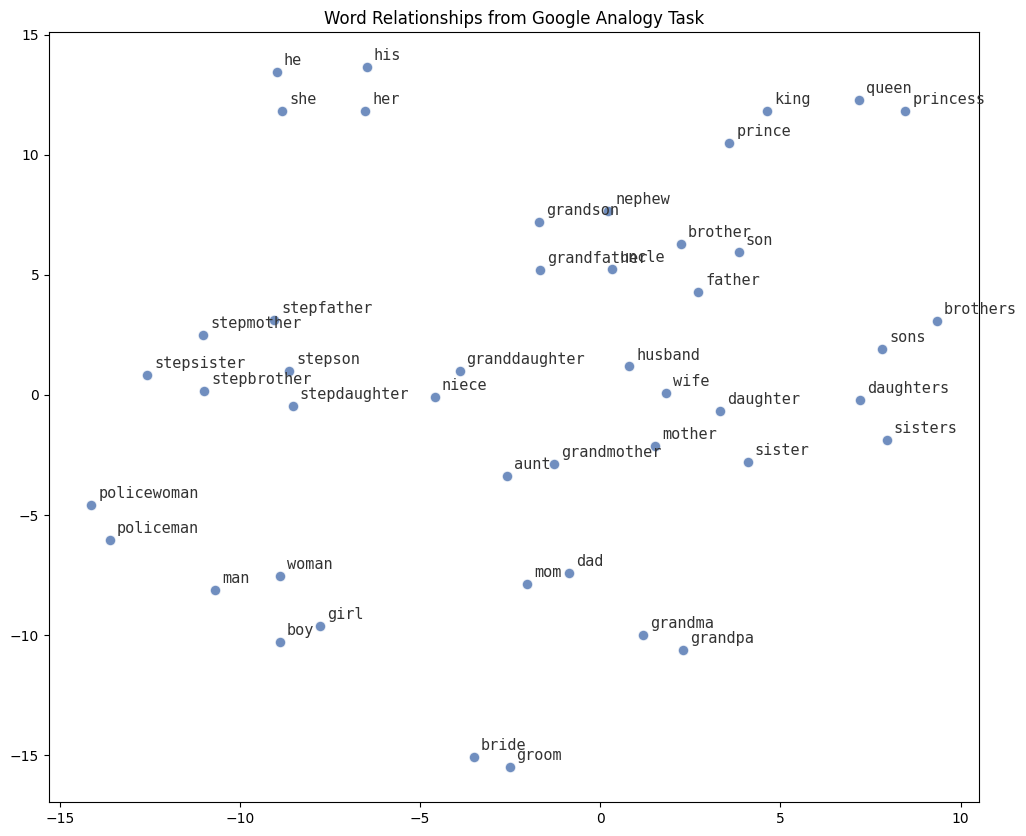

<Figure size 640x480 with 0 Axes>

In [ ]:
"""AI-assisted code snippet"""


# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO3: Plot t-SNE for the words in the SUB_CATEGORY `: family`
family_questions = data[data["SubCategory"] == SUB_CATEGORY]["Question"]
words = []
for question in family_questions:
    for w in question.lower().split():
        if w not in words:
            words.append(w)

# Only words that appear in the model vocabular are retained
words = [w for w in words if w in model.key_to_index]
vectors = np.array([model[w] for w in words])

#t-SNE
tsne = TSNE(n_components=2, perplexity=10, random_state=42)
vectors_2d = tsne.fit_transform(vectors)

# Plots: For better readability, I consulted Claude to refine the formats of the plots.
# More specifically, I modified the font size, location of caption, and the color of the plot.
plt.figure(figsize=(12, 10))
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1],
            s=60, color="#4C72B0", alpha=0.8, edgecolors="white")

for i, word in enumerate(words):
    plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]),
                 xytext=(5, 5), textcoords="offset points",
                 fontsize=11, color="#333333", fontfamily="monospace")

plt.title("Word Relationships from Google Analogy Task")
plt.savefig("word_relationships.png", bbox_inches="tight")
plt.show()

### Part III: Train your own word embeddings

### Get the latest English Wikipedia articles and do sampling.
- Usually, we start from Wikipedia dump (https://dumps.wikimedia.org/enwiki/latest/enwiki-latest-pages-articles.xml.bz2). However, the downloading step will take very long. Also, the cleaning step for the Wikipedia corpus ([`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus)) will take much time. Therefore, we provide cleaned files for you.

In [ ]:
# Gdown cannot access the files, possibly because too many people are downloading these files the same time?
# Anyways, I pivoted to adding shortcuts to my google drive. For this procedure, I consulted Claude by the way (use of generative AI).
from google.colab import drive
drive.mount("/content/drive")

!ls -lh /content/drive/MyDrive/NLP_HW1/

Mounted at /content/drive
total 6.5G
-r-------- 1 root root 1.5G Sep 17  2024 wiki_texts_part_0.txt.gz
-r-------- 1 root root 2.8K Sep 17  2024 wiki_texts_part_10.txt.gz
-r-------- 1 root root 798M Sep 17  2024 wiki_texts_part_1.txt.gz
-r-------- 1 root root 635M Sep 17  2024 wiki_texts_part_2.txt.gz
-r-------- 1 root root 568M Sep 17  2024 wiki_texts_part_3.txt.gz
-r-------- 1 root root 542M Sep 17  2024 wiki_texts_part_4.txt.gz
-r-------- 1 root root 552M Sep 17  2024 wiki_texts_part_5.txt.gz
-r-------- 1 root root 530M Sep 17  2024 wiki_texts_part_6.txt.gz
-r-------- 1 root root 506M Sep 17  2024 wiki_texts_part_7.txt.gz
-r-------- 1 root root 524M Sep 17  2024 wiki_texts_part_8.txt.gz
-r-------- 1 root root 522M Sep 17  2024 wiki_texts_part_9.txt.gz


In [ ]:
!cp /content/drive/MyDrive/NLP_HW1/wiki_texts_part_*.txt.gz .
!ls -lh wiki_texts_part_*.gz

-r-------- 1 root root 1.5G Oct 12 01:22 wiki_texts_part_0.txt.gz
-r-------- 1 root root 2.8K Oct 12 01:22 wiki_texts_part_10.txt.gz
-r-------- 1 root root 798M Oct 12 01:22 wiki_texts_part_1.txt.gz
-r-------- 1 root root 635M Oct 12 01:22 wiki_texts_part_2.txt.gz
-r-------- 1 root root 568M Oct 12 01:22 wiki_texts_part_3.txt.gz
-r-------- 1 root root 542M Oct 12 01:23 wiki_texts_part_4.txt.gz
-r-------- 1 root root 552M Oct 12 01:23 wiki_texts_part_5.txt.gz
-r-------- 1 root root 530M Oct 12 01:23 wiki_texts_part_6.txt.gz
-r-------- 1 root root 506M Oct 12 01:23 wiki_texts_part_7.txt.gz
-r-------- 1 root root 524M Oct 12 01:23 wiki_texts_part_8.txt.gz
-r-------- 1 root root 522M Oct 12 01:23 wiki_texts_part_9.txt.gz


In [ ]:
# Extract the downloaded wiki_texts_parts files.
!gunzip -k wiki_texts_part_*.gz

In [ ]:
# Combine the extracted wiki_texts_parts files.
!cat wiki_texts_part_*.txt > wiki_texts_combined.txt

In [ ]:
# Check the first ten lines of the combined file
!head -n 10 wiki_texts_combined.txt

anarchism is political philosophy and movement that is against all forms of authority and seeks to abolish the institutions it claims maintain unnecessary coercion and hierarchy typically including the state and capitalism anarchism advocates for the replacement of the state with stateless societies and voluntary free associations as historically left wing movement this reading of anarchism is placed on the farthest left of the political spectrum usually described as the libertarian wing of the socialist movement libertarian socialism although traces of anarchist ideas are found all throughout history modern anarchism emerged from the enlightenment during the latter half of the th and the first decades of the th century the anarchist movement flourished in most parts of the world and had significant role in workers struggles for emancipation various anarchist schools of thought formed during this period anarchists have taken part in several revolutions most notably in the paris commune

In [ ]:
!rm wiki_texts_part_*.txt wiki_texts_part_*.gz
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   49G   60G  45% /


Please note that we used the default parameters of [`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus) for cleaning the Wiki raw file. Thus, words with one character were discarded.

In [ ]:
# Now you need to do sampling because the corpus is too big.
# You can further perform analysis with a greater sampling ratio.

import random

random.seed(42)
sample_ratio = 0.2
# {0.05, 0.1}

wiki_txt_path = "wiki_texts_combined.txt"
# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.
output_path = "wiki_texts_sampled_20.txt"

sampled_count = 0

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # TODO4: Sample `20%` Wikipedia articles
    # Write your code here
      for line in f:
        if random.random() < sample_ratio:
          output_file.write(line)
          sampled_count += 1

print("With the sample ratio =", sample_ratio, ", The amount of articles sampled is", sampled_count)

With the sample ratio = 0.2 , The amount of articles sampled is 1124733


In [ ]:
# TODO5: Train your own word embeddings with the sampled articles
# https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec
# Hint: You should perform some pre-processing before training.

In [12]:
from gensim.models import Word2Vec
import os

In [ ]:
# Pre-processing:
import re
from tqdm import tqdm

english_word = re.compile(r"^[a-z]+$") # This is carried out so that only english words are retained.
# The others are effectively screened out

input_path  = "wiki_texts_sampled_20.txt"
output_path = "wiki_texts_sampled_20_clean.txt"

with open(input_path, "r", encoding="utf-8") as f_in, \
     open(output_path, "w", encoding="utf-8") as f_out:
    for line in tqdm(f_in):
        tokens = [w for w in line.split() if english_word.match(w)]
        if tokens:
            f_out.write(" ".join(tokens) + "\n")

1124733it [09:52, 1898.99it/s]


In [ ]:
# Model building
# Using Word2Vec (CBOW) for the analogy task
my_model = Word2Vec(
    corpus_file="wiki_texts_sampled_20_clean.txt",
    vector_size=100,
    window=5,
    min_count=5,
    # Words appearing fewer than 5 times are filtered out
    max_final_vocab=300000,
    # Vocabulary capped at 300,000 words
    sg=0,
    # CBOW
    epochs=5,
    workers=os.cpu_count(),
)
my_model.save(f"{fail_save_dir}/w2v_wiki20.model")
print("Vocabulary size:", len(my_model.wv))

Vocabulary size: 293294


In [ ]:
!ls -lh /content/drive/MyDrive/NLP_HW1/

total 6.7G
-rw------- 1 root root 9.0M Oct 12 07:02 w2v_wiki20.model
-rw------- 1 root root 112M Oct 12 07:02 w2v_wiki20.model.syn1neg.npy
-rw------- 1 root root 112M Oct 12 07:02 w2v_wiki20.model.wv.vectors.npy
-r-------- 1 root root 1.5G Sep 17  2024 wiki_texts_part_0.txt.gz
-r-------- 1 root root 2.8K Sep 17  2024 wiki_texts_part_10.txt.gz
-r-------- 1 root root 798M Sep 17  2024 wiki_texts_part_1.txt.gz
-r-------- 1 root root 635M Sep 17  2024 wiki_texts_part_2.txt.gz
-r-------- 1 root root 568M Sep 17  2024 wiki_texts_part_3.txt.gz
-r-------- 1 root root 542M Sep 17  2024 wiki_texts_part_4.txt.gz
-r-------- 1 root root 552M Sep 17  2024 wiki_texts_part_5.txt.gz
-r-------- 1 root root 530M Sep 17  2024 wiki_texts_part_6.txt.gz
-r-------- 1 root root 506M Sep 17  2024 wiki_texts_part_7.txt.gz
-r-------- 1 root root 524M Sep 17  2024 wiki_texts_part_8.txt.gz
-r-------- 1 root root 522M Sep 17  2024 wiki_texts_part_9.txt.gz


In [ ]:
!cp wiki_texts_sampled_20_clean.txt {fail_save_dir}/

In [ ]:
data = pd.read_csv("questions-words.csv")

In [ ]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []
oov_count = 0
# as in "out of vocabulary count"

for analogy in tqdm(data["Question"]):
      # TODO6: Write your code here to use your trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      word_a, word_b, word_c, word_d = analogy.lower().split()
      golds.append(word_d)
      try:
        pred = my_model.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
      except KeyError:
        pred = None
        oov_count += 1
      preds.append(pred)


print("The number of Questions with out-of-vocabulary words:", oov_count)

100%|██████████| 19544/19544 [06:26<00:00, 50.51it/s]

The amount of Questions with out-of-vocabulary words: 33


In [ ]:
# Perform evaluations.
# This code block is just copy-pasted from above.

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 64.69726011951742%
Category: syntactic, Accuracy: 51.24121779859485%
Sub-Category: capital-common-countries, Accuracy: 80.8300395256917%
Sub-Category: capital-world, Accuracy: 76.81255526083113%
Sub-Category: currency, Accuracy: 14.780600461893764%
Sub-Category: city-in-state, Accuracy: 52.33076611268748%
Sub-Category: family, Accuracy: 85.96837944664031%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 20.967741935483872%
Sub-Category: gram2-opposite, Accuracy: 16.379310344827587%
Sub-Category: gram3-comparative, Accuracy: 70.7957957957958%
Sub-Category: gram4-superlative, Accuracy: 39.57219251336899%
Sub-Category: gram5-present-participle, Accuracy: 45.73863636363637%
Sub-Category: gram6-nationality-adjective, Accuracy: 80.98811757348344%
Sub-Category: gram7-past-tense, Accuracy: 48.97435897435897%
Sub-Category: gram8-plural, Accuracy: 55.63063063063063%
Sub-Category: gram9-plural-verbs, Accuracy: 52.758620689655174%


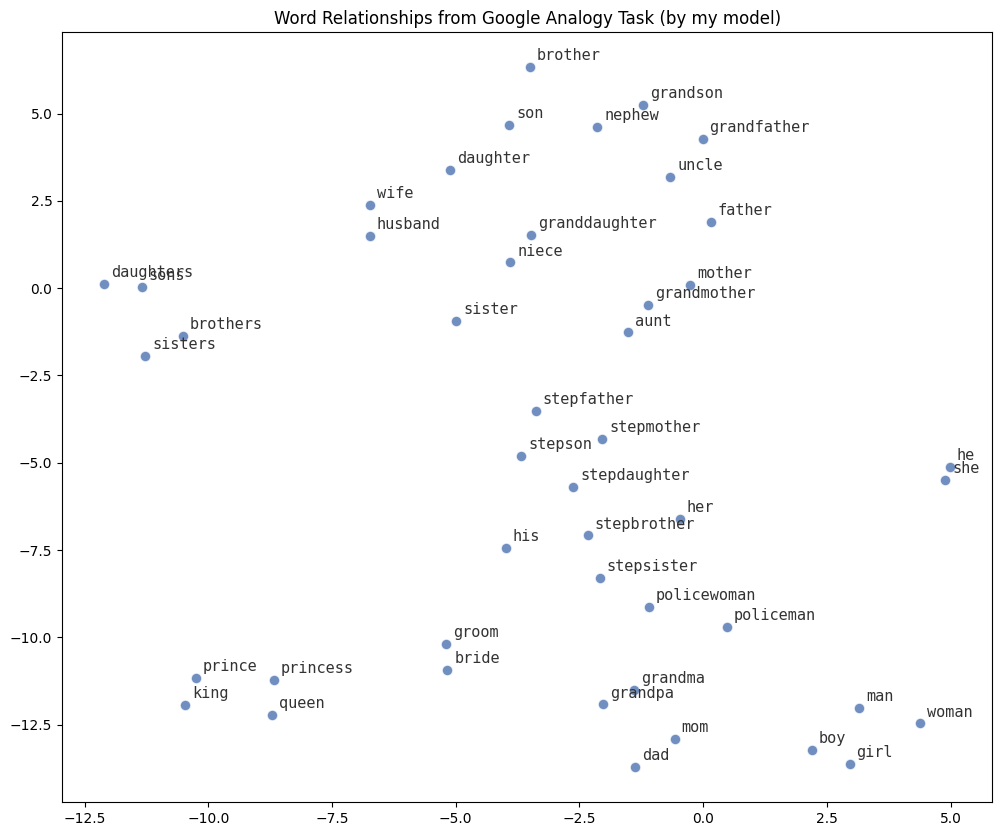

<Figure size 640x480 with 0 Axes>

In [ ]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO7: Plot t-SNE for the words in the SUB_CATEGORY `: family`
family_questions = data[data["SubCategory"] == SUB_CATEGORY]["Question"]
words = []
for question in family_questions:
    for w in question.lower().split():
        if w not in words:
            words.append(w)

# Only words that appear in the model vocabulary are retained
words = [w for w in words if w in my_model.wv.key_to_index]
vectors = np.array([my_model.wv[w] for w in words])

#t-SNE
tsne = TSNE(n_components=2, perplexity=10, random_state=42)
vectors_2d = tsne.fit_transform(vectors)

plt.figure(figsize=(12, 10))
plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1],
            s=60, color="#4C72B0", alpha=0.8, edgecolors="white")
for i, word in enumerate(words):
    plt.annotate(word, (vectors_2d[i, 0], vectors_2d[i, 1]),
                 xytext=(5, 5), textcoords="offset points",
                 fontsize=11, color="#333333", fontfamily="monospace")


plt.title("Word Relationships from Google Analogy Task (by my model)")
plt.savefig("word_relationships_my_model.png", bbox_inches="tight")
plt.show()

Running environment: Google Colab (CPU)

Python version: 3.13 (gensim 4.4.0)

#### Q1. Which embedding model do you use? What are the pre-processing steps? What are the hyperparameter settings? (5%)
Answer:

**[Embedding Models]:**

* Part 2 (pre-trained model): `glove-wiki-gigaword-100` (A 100-dimensional GloVe model and the gifaword 5 newswire corpus)
As for the self-trained model (part 3), I used the genism Word_2_Vec model, given that it's supposed to outperform others in scenarios where corpus is of big zie.
CBOW (continuos bag of words) is employed, for there are likely frequent words in Wikipeia. And CBOW is better than skip-gram in large corpus.

* Part 3 (self-trained models): gensim `Word2Vec` with the CBOW structure (`sg = 0`). I chose Word2Vec over other models for this task, considering that gensim can train the models on a large corpus more efficiently. And
`CBOW` is employed, for it trains several times faster on larger corpus (compared to `skip-gram`).

**[Pre-processing]**

1. The provided Wikipedia files had already been cleaned by `WikiCorpus` with its default parameters (lowercased, punctuation removed, words with only a single character removed).
2. 20% of the articles were randomly sampled without replacement (`random.seed(42)`), which gives 1,124,733 articles in total.
3. Only purely alphabetic tokens (regex `^[a-z]+$`) were retained; the tokens containing digits or non-English characters were screened out.
4. The analogy questions were lowercased so that they match the lowercase vocabulary of the models.
5. Only the most frequent words were retained in the dictionary, through `min_count` and `max_final_vocab` (see below).
6. Lemmatization was not applied, and stop words were not removed, for stop words contain some words required in the `family` subcategory (e.g. `he`, `she`, `his`, `her`). Lemmatization reduces words to their lemma (the base form), which would render the syntactic questions impossible to answer.


**[Hyperparameters of the self-trained Wikipedia model]**

| Parameter | Value | Note |
|---|---:|---|
| `vector_size` | 100 | Same dimension as the GloVe model, for a fair comparison |
| `window` | 5 |  |
| `min_count` | 5 | Words appearing fewer than 5 times are removed |
| `max_final_vocab` | 300,000 | The dictionary retains at most 300,000 of the most frequent words |
| `sg` | 0 | CBOW |
| `epochs` | 5 |  |
| `workers` | `os.cpu_count()` | Parallel training |

The final vocabulary size of the 20% model: 293,294 words.

For the two extra corpora in Q3 (Brown and ML-ArXiv), which are much smaller, I changed three settings: `min_count=2` (otherwise too few words would remain), `sg=1` (for Skip-gram usually handles rare words better on small corpora) and `epochs=10` (more passes to make up for less data). The other settings are the pretty much the same.

#### Q2. What will the performance be like if you sample 5%, 10% and 20% of wiki text in TODO4? (10%, 3% for each)

**Answer:**

**Table 2.1: Corpus size**

| | 5% | 10% | 20% |
|---|---:|---:|---:|
| Number of articles | 280,783 | 562,128 | 1,124,733 |
| Vocabulary size | 279,580 | 293,730 | 293,294 |

**Table 2.2: Accuracy (%)**

| | 5% | 10% | 20% |
|---|---:|---:|---:|
| semantic | 60.15 | 62.79 | 64.70 |
| syntactic | 47.16 | 49.98 | 51.24 |
| capital-common-countries | 83.00 | 81.23 | 80.83 |
| capital-world | 73.81 | 76.81 | 76.81 |
| currency | 8.89 | 11.89 | 14.78 |
| city-in-state | 44.83 | 47.06 | 52.33 |
| family | 77.67 | 82.81 | 85.97 |
| gram1-adjective-to-adverb | 20.26 | 21.37 | 20.97 |
| gram2-opposite | 13.67 | 16.63 | 16.38 |
| gram3-comparative | 63.06 | 70.95 | 70.80 |
| gram4-superlative | 34.94 | 38.77 | 39.57 |
| gram5-present-participle | 41.19 | 43.84 | 45.74 |
| gram6-nationality-adjective | 79.55 | 80.24 | 80.99 |
| gram7-past-tense | 43.53 | 46.60 | 48.97 |
| gram8-plural | 52.63 | 51.95 | 55.63 |
| gram9-plural-verbs | 46.32 | 50.92 | 52.76 |

**Observations (Analysis)**

1. Overall, the more data is sampled to trained a model, the better it performs. Both semantic and syntactic accuracy increase at every step.
2. It's noteworthy that the gains get smaller. Semantic accuracy improves by 2.64 points from 5% to 10%, but only 1.91 points from 10% to 20%. Syntactic accuracy improves by 2.82 and then 1.26 points. Doubling the data again brings less improvement (from 10% to 20%).
3. Such increases (gains) of accuracies are most evident in subcategories with rare words: Currency (8.89 to 14.78), family (+8.30), city-in-state (+7.50) and plural-verbs (+6.44). Many currency names and small US cities appear only a few times in a small sample, so their vectors get better as more examples are added.

4. Let it be noted, however, that such increases are not universal. For some sub-categories, the accuracies barely change as the sampling ratio scales up. It's likely that for some subcategories, such as `capitals` and `nationality adjectives`, the words are very frequent in Wikipedia, and that they are hence already learned well at 5%.  In a few subcategories the 10% model is even slightly better than the 20% model (opposite, comparative, adjective-to-adverb), but the differences are rather subtle.

5. The vocabulary grows from 279,580 (5%) to about 293,000 (10%) and then stays almost the same, likely because it reaches the max cap of vocabulary (300000, as previously shown). The small difference between 293,730 and 293,294 comes from how gensim raises the minimum count to stay under the limit. It can be inferred that the improvement from 10% to 20% comes from having more training examples for the same words (not from learning new words).

**Notes (About the sampling methods):**

To save time, the 5% and 10% samples were drawn from the cleaned 20% sample with ratios of 0.25 and 0.5, using one random number per article (code below). Each article is therefore included with probability 0.2 * 0.25 = 0.05 or 0.2 * 0.5 = 0.1, which is equivalent to sampling directly from the full corpus.

In [5]:
from gensim.models import Word2Vec
# Importing models from my google drive
my_model = Word2Vec.load(f"{fail_save_dir}/w2v_wiki20.model")
brown_model = Word2Vec.load(f"{fail_save_dir}/w2v_brown.model")
ml_model = Word2Vec.load(f"{fail_save_dir}/w2v_ml.model")

In [ ]:
# Q2: Sample 5% and 10% from the 20% sample
import random
random.seed(42)

src = "wiki_texts_sampled_20_clean.txt"
count_5, count_10 = 0, 0

with open(src, "r", encoding="utf-8") as f_in, \
     open("wiki_texts_sampled_5_clean.txt", "w", encoding="utf-8") as f5, \
     open("wiki_texts_sampled_10_clean.txt", "w", encoding="utf-8") as f10:
    for line in f_in:
        r = random.random()
        if r < 0.25:
          # 0.2 * 0.25 = 5% of the full corpus
            f5.write(line)
            count_5 += 1
        if r < 0.5:
          # 0.2 * 0.5 = 10% of the full corpus
            f10.write(line)
            count_10 += 1

print("5% articles:", count_5)
print("10% articles:", count_10)

# The hyperparameters are exactly the same with the 20% one
for pct in [5, 10]:
    m = Word2Vec(
        corpus_file=f"wiki_texts_sampled_{pct}_clean.txt",
        vector_size=100, window=5, min_count=5,
        max_final_vocab=300000, sg=0, epochs=5,
        workers=os.cpu_count(),
    )
    m.save(f"{fail_save_dir}/w2v_wiki{pct}.model")
    print(f"The {pct}% model saved, vocabulary size:", len(m.wv))

5% articles: 280783
10% articles: 562128
The 5% model saved, vocabulary size: 279580
The 10% model saved, vocabulary size: 293730


In [13]:
# Q2: Evaluate the 5% model
model_5 = Word2Vec.load(f"{fail_save_dir}/w2v_wiki5.model")

preds = []
golds = []

for analogy in tqdm(data["Question"]):
    word_a, word_b, word_c, word_d = analogy.lower().split()
    golds.append(word_d)
    try:
        pred = model_5.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
    except KeyError:
        pred = None
    preds.append(pred)

100%|██████████| 19544/19544 [05:49<00:00, 55.99it/s]


In [14]:
# Perform evaluations for the 5% model
# This code block is just copy-pasted from above.

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 60.15334310519788%
Category: syntactic, Accuracy: 47.156908665105384%
Sub-Category: capital-common-countries, Accuracy: 83.00395256916995%
Sub-Category: capital-world, Accuracy: 73.80636604774536%
Sub-Category: currency, Accuracy: 8.891454965357967%
Sub-Category: city-in-state, Accuracy: 44.83177948925821%
Sub-Category: family, Accuracy: 77.66798418972331%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 20.262096774193548%
Sub-Category: gram2-opposite, Accuracy: 13.669950738916256%
Sub-Category: gram3-comparative, Accuracy: 63.06306306306306%
Sub-Category: gram4-superlative, Accuracy: 34.93761140819964%
Sub-Category: gram5-present-participle, Accuracy: 41.19318181818182%
Sub-Category: gram6-nationality-adjective, Accuracy: 79.54971857410882%
Sub-Category: gram7-past-tense, Accuracy: 43.52564102564103%
Sub-Category: gram8-plural, Accuracy: 52.627627627627625%
Sub-Category: gram9-plural-verbs, Accuracy: 46.32183908045977%


In [15]:
# Q2: Evaluate the 10% model
model_10 = Word2Vec.load(f"{fail_save_dir}/w2v_wiki10.model")

preds = []
golds = []

for analogy in tqdm(data["Question"]):
    word_a, word_b, word_c, word_d = analogy.lower().split()
    golds.append(word_d)
    try:
        pred = model_10.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
    except KeyError:
        pred = None
    preds.append(pred)

100%|██████████| 19544/19544 [05:00<00:00, 64.98it/s]


In [17]:
# Perform evaluations for the 10% model
# This code block is just copy-pasted from above.

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 62.791746532867286%
Category: syntactic, Accuracy: 49.976580796252925%
Sub-Category: capital-common-countries, Accuracy: 81.22529644268775%
Sub-Category: capital-world, Accuracy: 76.81255526083113%
Sub-Category: currency, Accuracy: 11.893764434180138%
Sub-Category: city-in-state, Accuracy: 47.061207944872315%
Sub-Category: family, Accuracy: 82.80632411067194%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 21.370967741935484%
Sub-Category: gram2-opposite, Accuracy: 16.625615763546797%
Sub-Category: gram3-comparative, Accuracy: 70.94594594594594%
Sub-Category: gram4-superlative, Accuracy: 38.770053475935825%
Sub-Category: gram5-present-participle, Accuracy: 43.84469696969697%
Sub-Category: gram6-nationality-adjective, Accuracy: 80.23764853033146%
Sub-Category: gram7-past-tense, Accuracy: 46.6025641025641%
Sub-Category: gram8-plural, Accuracy: 51.95195195195195%
Sub-Category: gram9-plural-verbs, Accuracy: 50.919540229885065%


#### Q3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

**3.1. Present your results. (5%)**

**Answer:**

I trained two extra models, one on the **Brown Corpus** and the other on the **ML-ArXiv-Papers** corpus (code below). They were compared with the Wikipedia 20% model above.

"Answerable questions" are questions in which all four words are in the model's vocabulary. Questions with out-of-vocabulary (OOV) words are counted as wrong. The overall and answerable accuracies were computed from the category accuracies presented below.

**Table 3.1: Accuracy (%) on different corpora**

| | Wiki 20% | Brown | ML-ArXiv |
|---|---:|---:|---:|
| Questions with OOV words (out of 19,544) | 33 | 9,435 | 9,903 |
| Overall | 57.35 | 1.26 | 6.23 |
| Accuracy on answerable questions | 57.44 | 2.44 | 12.62 |
| semantic | 64.70 | 0.76 | 0.18 |
| syntactic | 51.24 | 1.69 | 11.25 |
| capital-common-countries | 80.83 | 0.99 | 0.99 |
| capital-world | 76.81 | 0.02 | 0.13 |
| currency | 14.78 | 0.00 | 0.00 |
| city-in-state | 52.33 | 0.45 | 0.00 |
| family | 85.97 | 9.88 | 0.99 |
| gram1-adjective-to-adverb | 20.97 | 0.30 | 4.64 |
| gram2-opposite | 16.38 | 0.37 | 6.77 |
| gram3-comparative | 70.80 | 4.80 | 34.68 |
| gram4-superlative | 39.57 | 0.09 | 6.42 |
| gram5-present-participle | 45.74 | 1.52 | 17.71 |
| gram6-nationality-adjective | 80.99 | 0.50 | 0.94 |
| gram7-past-tense | 48.97 | 2.05 | 5.71 |
| gram8-plural | 55.63 | 2.78 | 3.45 |
| gram9-plural-verbs | 52.76 | 1.84 | 26.32 |

**3.2. Introduce the corpus you selected and explain what are the differences between the Wikipedia corpus and your corpus. (including data size, topic difference, structural difference …) (5%)**

**Answer:**

* **Brown Corpus** (from NLTK): about one million words of American English published in 1961. It contains 500 text samples from 15 genres, such as news, editorials, religion, fiction, mystery, science fiction, humor and academic ("learned") writing. I lowercased it and retained only alphabetic tokens.
* **ML-ArXiv-Papers** (Hugging Face, `CShorten/ML-ArXiv-Papers`): It contains titles and abstracts of 117,592 machine learning papers on arXiv. I used only the abstracts and processed them with `gensim.utils.simple_preprocess`.

**Table 3.2: Corpus statistics**

| | Wiki 20% | Brown | ML-ArXiv |
|---|---:|---:|---:|
| Total tokens | 665,871,740 | 981,716 | 19,572,115 |
| Unit of one line | article | sentence | abstract |
| Number of lines | 1,124,733 | 56,766 | 117,592 |
| Average tokens per line | 592.0 | 17.3 | 166.4 |
| Vocabulary size | 293,294 | 24,867 | 65,495 |

**Data size:** The Wikipedia sample is about 680 times larger than Brown and about 34 times larger than ML-ArXiv. Its vocabulary is about 12 times larger than Brown's and 5 times larger than ML-ArXiv's.

**Topic:** The 20 most frequent non-stop-words (code below) show the difference among them clearly:
* Wiki 20%: *also, first, new, year, school, world, city, national, team, university, american, state, united*. They are typical encyclopedia words that cover almost every topic.
* Brown: *would, said, could, time, like, man, even, made, back, years*. They are everyday words, many from story-telling and news reporting (*said*).
* ML-ArXiv: *learning, data, model, neural, training, methods, network, performance, propose, results, algorithm*. These belong to one narrow technical domain (machine learning).

**Structural differences**
* Wikipedia articles are long and descriptive, and contain many definition-style sentences about named entities.
* Brown is a mix of genres, including dialogue in fiction. Each line is a short sentence, as indicated by its average tokens per line.
* ML-ArXiv abstracts are short and follow a fixed pattern ("we propose ..., our method outperforms ..., experiments show ..."), and they contain many technical jargons and acronyms.
* There are also small differences in pre-processing: Brown keeps one-letter words (*a, i*), while Wikipedia and ML-ArXiv remove them.

**3.3. Explain why the performance increases or decreases. (5%)**

**Answer:**

Overall accuracy drops from 57.35% (Wiki 20%) to 6.23% (ML-ArXiv) and 1.26% (Brown). I think there are three reasons for this.

1. It's likely that the vocabulary coverage in the cases for the Brow and ML-ArXiv Corpora. About half of the questions contain at least one word that is not in the vocabulary. These questions are counted as wrong automatically. The semantic sub-categories need names of world capitals, currencies and US cities, which rarely appear in neither of the two chosen corpora.
2. The word frequency is likely a factor as well. Even among the answerable questions, accuracy is only 2.44% for Brown and 12.62% for ML-ArXiv (compared with 57.44% for Wikipedia). A word that appears only a few times does not get enough training updates, hence its vector is close to random and the offset *b − a + c* does not land on *d*.


3. It's possible that the topics of the corpus affect the performance to a certain extent. Given that each model learns mainly the relations that its corpus talks about, they likely grasp little about the relations outside the scope of their topic-of-interest.
   * Brown's best subcategory is family (9.88%), potentially because fiction and news often mention family members.
   * ML-ArXiv is much better on syntactic (11.25%) than semantic (0.18%) questions. Its best sub-categories are comparative (34.68%), plural-verbs (26.32%) and present-participle (17.71%). Papers constantly compare methods, and the plural-verbs questions include academic verbs. In contrast, ML-ArXiv performs poorly on plural nouns (3.45%), for those questions use everyday nouns. Within the same corpus, plural verbs work well and plural nouns do not, which shows that the topic of the corpus matters more than the grammar rule itself.


**Conclusion:** the quality of word embeddings depends more on whether the corpus contains enough occurrences of the words and relations being tested. The corpus size alone doesn't impact as much as it may seems to.

#### Code for Q3

In [5]:
# Q3.2:
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
stop_words = set(stopwords.words("english"))

for name, m in [("Wiki 20%", my_model), ("Brown", brown_model), ("ML-ArXiv", ml_model)]:
    print(name)
    print("Total tokens:", m.corpus_total_words)
    print("Vocabulary size:", len(m.wv))
    top_words = [w for w in m.wv.index_to_key if w not in stop_words][:20]
    print("Top 20 frequent words:", top_words)
    print()

Wiki 20%
Total tokens: 665871740
Vocabulary size: 293294
Top 20 frequent words: ['also', 'first', 'new', 'one', 'two', 'th', 'references', 'time', 'year', 'may', 'school', 'world', 'city', 'national', 'de', 'team', 'university', 'american', 'state', 'united']

Brown
Total tokens: 981716
Vocabulary size: 24867
Top 20 frequent words: ['one', 'would', 'said', 'new', 'could', 'time', 'two', 'may', 'first', 'like', 'man', 'even', 'made', 'also', 'many', 'must', 'af', 'back', 'years', 'much']

ML-ArXiv
Total tokens: 19572115
Vocabulary size: 65495
Top 20 frequent words: ['learning', 'data', 'model', 'based', 'models', 'neural', 'training', 'methods', 'network', 'performance', 'method', 'show', 'using', 'networks', 'paper', 'deep', 'propose', 'results', 'proposed', 'algorithm']



[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## Code For 3. What is the performance for different categories or sub-categories when trained on different corpora? (15%)

## **Corpus 1: Brown**




In [20]:
# Write your code here
import nltk
nltk.download("brown")
from nltk.corpus import brown

brown_sentences = 0
brown_tokens = 0

with open("brown_corpus.txt", "w", encoding="utf-8") as f:
    for sent in brown.sents():
        # Convert to lowercase
        # Only alphabetic words are retained
        B_words = [w.lower() for w in sent if w.isalpha()]
        if B_words:
            f.write(" ".join(B_words) + "\n")
            brown_sentences += 1
            brown_tokens += len(B_words)

print("Sentences:", brown_sentences)
print("Tokens:", brown_tokens)

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!


Sentences: 56766
Tokens: 981716


In [21]:
# Model Building...
brown_model = Word2Vec(
    corpus_file="brown_corpus.txt",
    vector_size=100,
    window=5,
    min_count=2,
    # Only words appearing at least twice are retained (which sets the bar lower than the case for Wikipedia), for this corpus is smaller in size
    sg=1,
    # Skip-gram works better on small corpora
    epochs=10,
    # more passes because there is less data
    workers=os.cpu_count(),
)
brown_model.save(f"{fail_save_dir}/w2v_brown.model")
print("Vocabulary size:", len(brown_model.wv))

Vocabulary size: 24867


In [22]:
# Evaluating the performance of the model (brown corpus): part 1
preds = []
golds = []
oov_count = 0

for analogy in tqdm(data["Question"]):
    word_a, word_b, word_c, word_d = analogy.lower().split()
    golds.append(word_d)
    try:
        pred = brown_model.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
    except KeyError:
        pred = None
        oov_count += 1
    preds.append(pred)

print("Questions with out-of-vocabulary words:", oov_count, "/", len(data))

100%|██████████| 19544/19544 [00:12<00:00, 1618.55it/s]

Questions with out-of-vocabulary words: 9435 / 19544


In [23]:
# Evaluating the performance of the model (brown corpus): part 2

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 0.7554402976660277%
Category: syntactic, Accuracy: 1.6861826697892273%
Sub-Category: capital-common-countries, Accuracy: 0.9881422924901186%
Sub-Category: capital-world, Accuracy: 0.022104332449160033%
Sub-Category: currency, Accuracy: 0.0%
Sub-Category: city-in-state, Accuracy: 0.4458856911228212%
Sub-Category: family, Accuracy: 9.881422924901186%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 0.3024193548387097%
Sub-Category: gram2-opposite, Accuracy: 0.3694581280788177%
Sub-Category: gram3-comparative, Accuracy: 4.804804804804805%
Sub-Category: gram4-superlative, Accuracy: 0.08912655971479501%
Sub-Category: gram5-present-participle, Accuracy: 1.5151515151515151%
Sub-Category: gram6-nationality-adjective, Accuracy: 0.5003126954346466%
Sub-Category: gram7-past-tense, Accuracy: 2.051282051282051%
Sub-Category: gram8-plural, Accuracy: 2.7777777777777777%
Sub-Category: gram9-plural-verbs, Accuracy: 1.839080459770115%


### **Corpus 2: ML ArXiv Papers**

In [27]:
!pip install datasets
from datasets import load_dataset
from gensim.utils import simple_preprocess

ds = load_dataset("CShorten/ML-ArXiv-Papers", split="train")
print(ds)

ml_abstracts = 0
ml_tokens = 0

with open("arxiv_ml_corpus.txt", "w", encoding="utf-8") as f:
    for row in ds:
        # simple_preprocess includes:
        # converting to lowercases
        # removes punctuation and numbers
        # tokenizes
        # drops tokens shorter than 2 or longer than 15 characters
        tokens = simple_preprocess(row["abstract"])
        if tokens:
            f.write(" ".join(tokens) + "\n")
            ml_abstracts += 1
            ml_tokens += len(tokens)

print("Abstracts:", ml_abstracts)
print("Tokens:", ml_tokens)

Dataset({
    features: ['Unnamed: 0.1', 'Unnamed: 0', 'title', 'abstract'],
    num_rows: 117592
})
Abstracts: 117592
Tokens: 19572115


In [28]:
# Model building...
ml_model = Word2Vec(
    corpus_file="arxiv_ml_corpus.txt",
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=10,
    workers=os.cpu_count(),
)
ml_model.save(f"{fail_save_dir}/w2v_ml.model")
print("Vocabulary size:", len(ml_model.wv))

Vocabulary size: 65495


In [29]:
# Evaluating the performance of the model (ML papers corpus): part 1
preds = []
golds = []
oov_count = 0

for analogy in tqdm(data["Question"]):
    word_a, word_b, word_c, word_d = analogy.lower().split()
    golds.append(word_d)
    try:
        pred = ml_model.wv.most_similar(positive=[word_b, word_c], negative=[word_a], topn=1)[0][0]
    except KeyError:
        pred = None
        oov_count += 1
    preds.append(pred)

print("Questions with out-of-vocabulary words:", oov_count, "/", len(data))

100%|██████████| 19544/19544 [00:33<00:00, 587.37it/s]

Questions with out-of-vocabulary words: 9903 / 19544


In [30]:
# Evaluating the performance of the model (ML papers corpus): part 2

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: semantic, Accuracy: 0.18040365317397677%
Category: syntactic, Accuracy: 11.250585480093676%
Sub-Category: capital-common-countries, Accuracy: 0.9881422924901186%
Sub-Category: capital-world, Accuracy: 0.1326259946949602%
Sub-Category: currency, Accuracy: 0.0%
Sub-Category: city-in-state, Accuracy: 0.0%
Sub-Category: family, Accuracy: 0.9881422924901186%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 4.637096774193548%
Sub-Category: gram2-opposite, Accuracy: 6.773399014778326%
Sub-Category: gram3-comparative, Accuracy: 34.68468468468468%
Sub-Category: gram4-superlative, Accuracy: 6.417112299465241%
Sub-Category: gram5-present-participle, Accuracy: 17.708333333333336%
Sub-Category: gram6-nationality-adjective, Accuracy: 0.9380863039399625%
Sub-Category: gram7-past-tense, Accuracy: 5.705128205128205%
Sub-Category: gram8-plural, Accuracy: 3.453453453453453%
Sub-Category: gram9-plural-verbs, Accuracy: 26.321839080459768%


#### Q4. Select at least five words and use their embeddings to retrieve the five most similar words. What do you observe? (10%)

**Answer:**

I chose five words and compared their five nearest neighbors in three models (GloVe, my Wikipedia 20% model and the ML-ArXiv model. The code and full output are presented below ), including *king*, *good*, *network*, *learning* and *taiwan*.

**Table 4.1: Five most similar words (pt.1)**

| Word | GloVe | Wiki 20% | ML-ArXiv |
|---|---|---|---|
| king | prince, queen, son, brother, monarch | prince, ethelred, monarch, queen, unready | kings, glory, netease, euroleague, legends |
| good | better, sure, really, kind, very | bad, decent, perfect, tough, fickle | satisfactory, excellent, reasonable, poor, adequate |
| network | networks, cable, channel, broadcast, channels | networks, channel, iptv, nsfnet, mmds | networks, hlconcfnn, ddnn, weightless, rcrnn |
| learning | teaching, knowledge, experience, skills, learn | learner, teaching, learners, cognition, experiential | eml, omrl, cdrl, fedfsl, cdadrl |
| taiwan | mainland, china, taiwanese, taipei, hong | china, japan, singapore, philippines, cambodia | taiwanese, saudi, vietnam, favorita, miutsu |


**Observations:**

1. The `most_similar` functions returns words used in similar context. They are not necessarily close in meaning. The neighbors of *king* are related words (*prince, queen, monarch*). In the Wiki 20% model, *taiwan* is closest to other Asian countries, which are words of the same type. In GloVe, however, *taiwan* is closest to *mainland, china, taipei*, which probably reflects how often news articles discuss these places together. It is also observed that opposites can be the most similar words. In the Wiki 20% model the nearest neighbor of *good* is *bad*, and the ML-ArXiv model also lists *poor*. Opposites appear in the same contexts, hence they get similar vectors and, by extension, get to be the "most similar" words with each other despite the semantic differences.
2. The topics of a corpus decides the meaning of a word. For *network*, GloVe (which includes news) gives TV broadcasting words (*cable, channel, broadcast*). The Wiki 20% model mixes TV and computer networks terminologies (*channel, iptv, nsfnet*). The ML-ArXiv model gives neural network model names (*ddnn, rcrnn, weightless*).
The same goes for *learning*, as GloVe gives terms related with education (*teaching, learners, cognition*), whereas ML-ArXiv gives machine learning methods in ML-ArXiv (*omrl, cdrl, fedfsl*).
3. Many ML-ArXiv neighbours are rare acronyms (*eml, omrl*) or usual words (*mintsu, favorita*). I suppose this has something do with the fact that I used `min_count=2` and skip-gram. Words that appear only a few times are retained, and a single shared context can make them appear very similar. A small corpus more likely gives noisy neighbours. A higher `min_count` would probably give cleaner neighbours, but it would also increase the number of OOV words in the analogy task (which is not ideal, considering that the corpus size ML-ArXiv already shrinks to the half to its original size when `min_count=2`).

**Table 4.2: Eleven most similar words (pt.2)**
| Word | GloVe | Wiki 20% | ML-ArXiv |
|---|---|---|---|
| model | models, design, concept, prototype, introduced | models, fto, concept, memristor, mpv | models, latticernn, ilmt, camero, mystyle |
| performance | performances, best, quality, success, well | performances, showmanship, choreography, presentation, musicianship | performances, accuracy, accuracies, generalight, robustness |
| bias | prejudice, biased, perception, discrimination, racism | biases, salience, biased, acceptability, negativity | biases, unfairness, cofounding, biased, variance |
| train | trains, bus, rails, buses, passengers | trains, bus, passenger, derails, tram | trained, learn, trains, deploy, build |
| apple | microsoft, ibm, intel, software, dell | iigs, blackberry, oreo, ibook, imac | cedar, rekognition, photographing, osps, gaen |
| pipeline | pipelines, gas, oil, lng, caspian | pipelines, enbridge, subsea, gas, lng | workflow, pipelines, plumber, smlt, workflows |
| cluster | clusters, bomblets, globular, bombs, small | cluster, globular, hyades, component, fornax | clusters, regroup, clustering, partition, centroid |
| crush | quell, bloody, crackdown, rebellion, crack | crushes, cheated, dotes, cheats, stranglehold | frap, absur, maintainer, lemonade, mivor |
| field | fields, ground, first, ball, well | nishigaoka, safeco, fields, usf, centurylink | fields, strf, developments, vibraint, research |
| resolution | resolutions, declaration, compromise, proposal, measure | resolutions, unsc, declaration, directive, constitution | mstr, resolutions, vhr, uhr, hstr |
| drive | drives, push, turn, run, driven | ride, drives, run, pass, walk | enact, reconnect, guide, locomote, steer |


**Notes:**

1. This is another set of words for comparison, which showcases clearer differences between the three corpora.

2. Polysemies, Homonymes, and Heterosemies are the most reliable tells for the topics-of-interests for each corpus. This is especially evident in the case of *model* and *performance*, where neighbor sets show almost no overlap across the three models.
Take the word *model* for example, the GloVe gives generic and conceptual terms (*design, concept, prototype*), reflecting general usage in news contexts (*such as fashion, business, or conceptual frameworks*).

The Wiki 20% model outputs broader terms, including acronyms like fto, which can stand for distinct concepts depending on domain ("Flexible Time Off", "Field Training Officer", or "Freedom to Operate").
On the other hand, the Wiki 20% model gives broader terms. *fto* carries widely different meanings across different domains ("Flexible time off" as a corporate jargon, "Field training officer" in the domain of law enforcement, "Freedom to Operate" as a law or business term).
The ML-ArXiv model captures *model* specifically as a machine learning architecture, returning specific deep learning model names and related acronyms.


3. Simply put, words whose meanings shift dramatically across different contexts provide reliable tells for inferring the underlying topic distribution of a corpus.

In [8]:
# For Q4 (pt.2)
words_to_check = ["model", "performance", "bias", "train", "apple", "pipeline", "cluster", "crush", "field", "resolution", "drive"]

for name, kv in [("GloVe", model), ("Wiki 20%", my_model.wv), ("ML-ArXiv", ml_model.wv)]:
    print(name)
    for w in words_to_check:
        if w in kv.key_to_index:
            print(" ", w, "->", [x for x, _ in kv.most_similar(w, topn=5)])
        else:
            print(" ", w, "-> (not in vocabulary)")
    print()

GloVe
  model -> ['models', 'design', 'concept', 'prototype', 'introduced']
  performance -> ['performances', 'best', 'quality', 'success', 'well']
  bias -> ['prejudice', 'biased', 'perception', 'discrimination', 'racism']
  train -> ['trains', 'bus', 'rail', 'buses', 'passenger']
  apple -> ['microsoft', 'ibm', 'intel', 'software', 'dell']
  pipeline -> ['pipelines', 'gas', 'oil', 'lng', 'caspian']
  cluster -> ['clusters', 'bomblets', 'globular', 'bombs', 'small']
  crush -> ['quell', 'bloody', 'crackdown', 'rebellion', 'crack']
  field -> ['fields', 'ground', 'first', 'ball', 'well']
  resolution -> ['resolutions', 'declaration', 'compromise', 'proposal', 'measure']
  drive -> ['drives', 'push', 'turn', 'run', 'driven']

Wiki 20%
  model -> ['models', 'fto', 'concept', 'memristor', 'mpv']
  performance -> ['performances', 'showmanship', 'choreography', 'presentation', 'musicianship']
  bias -> ['biases', 'salience', 'biased', 'acceptability', 'negativity']
  train -> ['trains', 'bu

In [6]:
# For Q4 (pt.1)
words_to_check = ["king", "good", "network", "learning", "taiwan"]

for name, kv in [("GloVe", model), ("Wiki 20%", my_model.wv), ("ML-ArXiv", ml_model.wv)]:
    print(name)
    for w in words_to_check:
        if w in kv.key_to_index:
            print(" ", w, "->", [x for x, _ in kv.most_similar(w, topn=5)])
        else:
            print(" ", w, "-> (not in vocabulary)")
    print()

GloVe
  king -> ['prince', 'queen', 'son', 'brother', 'monarch']
  good -> ['better', 'sure', 'really', 'kind', 'very']
  network -> ['networks', 'cable', 'channel', 'broadcast', 'channels']
  learning -> ['teaching', 'knowledge', 'experience', 'skills', 'learn']
  taiwan -> ['mainland', 'china', 'taiwanese', 'taipei', 'hong']

Wiki 20%
  king -> ['prince', 'ethelred', 'monarch', 'queen', 'unready']
  good -> ['bad', 'decent', 'perfect', 'tough', 'fickle']
  network -> ['networks', 'channel', 'iptv', 'nsfnet', 'mmds']
  learning -> ['learner', 'teaching', 'learners', 'cognition', 'experiential']
  taiwan -> ['china', 'japan', 'singapore', 'philippines', 'cambodia']

ML-ArXiv
  king -> ['kings', 'glory', 'netease', 'euroleague', 'legends']
  good -> ['satisfactory', 'excellent', 'reasonable', 'poor', 'adequate']
  network -> ['networks', 'hlconcfnn', 'ddnn', 'weightless', 'rcrnn']
  learning -> ['eml', 'omrl', 'cdrl', 'fedfsl', 'cdadrl']
  taiwan -> ['taiwanese', 'saudi', 'vietnam', 'fa

#### Q5. … Anything that can strengthen your report. (5%)

**Answer:**




**5.1. Pre-trained GloVe vs. my Wikipedia 20% model**

| | GloVe (Part II) | Wiki 20% (Part III) |
|---|---:|---:|
| semantic | **65.34** | 64.70 |
| syntactic | **61.26** | 51.24 |
| capital-common-countries | **93.87** | 80.83 |
| city-in-state | 30.81 | **52.33** |
| family | 81.62 | **85.97** |
| gram5-present-participle | **69.51** | 45.74 |
| gram8-plural | **72.00** | 55.63 |

* The two models are almost equal on semantic questions, but GloVe is about 10 points better on `syntactic` questions. I suppose this has something to do with the number of examples in each corpus. Syntactic relations (word endings such as *-ing* and plurals) seem to need many examples of each word form, which may explain why GloVe outperforms the wiki 20% model of mine.
* My wiki 20% model outperforms GloVe on `city-in-state` (52.33% vs. 30.81%). I suspect this is more associated with the topic of each corpus.
The wiki corpus contains thousands of articles that start with sentences like "X is a city in Y County, Z", while GloVe's training data also includes a large amount of newswire.
* GloVe is better on `capitals`, probably because news articles mention countries and their capitals much more often.


**5.2. Comparing the two t-SNE plots (TODO3 and TODO7)**

* In both plots, the family words are grouped by type of relation rather than by gender: royalty (*king, queen, prince, princess*), step-family words, plural forms, informal words (*mom, dad, grandma, grandpa*), general words (*man, woman, boy, girl*) and *bride/groom*.
* Inside each group, the male and female words are next to each other (*king/queen, policeman/policewoman, stepbrother/stepsister*). This suggests a consistent direction in the vector space, which is why both models do well on the family sub-category (81.62% and 85.97%).
* In both plots, *mom/dad* are far from *mother/father* even though they mean the same thing. They are used in different contexts (informal speech vs. formal writing), so the embeddings also learn the register of a word.

#### Q6. Generative AI Usage

**Answer:**

I consulted Claude on several occassions, as listed below.

**6.1. Code Snippets**
* Assisted in downloading the Wiki corpus and saving the trained models and processed datasets to Google Drive.
* Debugged code snippets associated with plotting results.

All AI-assisted code blocks are marked within the blocks themselves.

**6.2 Reports**
* Provided formatting assistance for all tables presented above (Tables in Sections 2.1, 2.2, 3.1, 3.2, 4.1, and 5.1).

* Proofread text for grammatical errors (and for terminology misuse).



